# WeatherML

## Setup & configuration

### Import Libraries

In [59]:
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

### Set Constants

In [60]:
COLOR_MAPPING = {
    'none': 'red',
    'jacket-short': 'orange',
    'jacket-long': 'green',
    'coat': 'blue'
}

RANDOM_STATE = 17

MONTHS = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December'
]

### Load Dataset

In [61]:
df = pd.read_csv('weather_data.csv')
print('# Records:', df.shape[0])
print('# Features:', df.shape[1])
df.head()

# Records: 630
# Features: 9


,Date,Time,Temp (°F),Feels Like (°F),Humidity (%),UV,Wind (mph),Gusts (mph),Outer Clothing
0,07/11/2023,13:55,80,80,44,9,4,NaN,none
1,07/12/2023,12:44,83,83,45,9,4,NaN,none
2,07/13/2023,20:15,75,78,79,0,4,NaN,none
3,07/17/2023,17:38,82,83,49,3,5,NaN,none
4,07/22/2023,18:03,75,76,58,2,4,NaN,none


I have **630** data records with **9** starting features (including the target variable).

## Data Processing
Before I can do any sort of machine learning, I need to first examine my dataset
and preprocess it. This involves feature engineering and handling missing values.

### Format Column Names
Here, I'm processing the column names to make coding easier down the
road. This involves:
- Removing units from labels
- Concatenating multiple words into snake_case
- Shifting all to lowercase

In [62]:
label_map = {
    'Temp (°F)': 'Temp',
    'Feels Like (°F)': 'Feels_Like',
    'Humidity (%)': 'Humidity',
    'Wind (mph)': 'Wind',
    'Gusts (mph)': 'Gusts',
    'Outer Clothing': 'label'
}
df.rename(columns=label_map, inplace=True)
df.columns = df.columns.str.lower()

### Date Type Cleaning
I'm also converting *Humidity* percentages from integer representation to decimals.
I convert *Date* from a string to an actual `datetime` object as well.

In [63]:
# convert humidity to decimal percents
df['humidity'] = df['humidity'] / 100

# convert dates to datetime
df['date'] = pd.to_datetime(df['date'])

### Add Season Data
I created a new feature to encapsulate the season data. I'm using simplified logic
that assigns a season based on the month alone, rather than using exact dates based
on solstices.

In [64]:
def get_season(date):
    if date.month in [12, 1, 2]:
        return 'winter'
    elif date.month in [3, 4, 5]:
        return 'spring'
    elif date.month in [6, 7, 8]:
        return 'summer'
    elif date.month in [9, 10, 11]:
        return 'fall'

df['season'] = [get_season(date_str) for date_str in df['date']]

### Cyclical Encoding
Both season and time are cycle periods, so cyclical encoding is used here to better
capture that nature. This makes the data representation more accurate for both
data analytics and ML training.

First, we cyclically encode the season.

In [65]:
mapping = {'winter': 0, 'spring': 1, 'summer': 2, 'fall': 3}

def cyclical_encode_season(season_str):
    season_num = mapping[season_str.lower()]
    radians = 2 * np.pi * season_num / 4
    return np.sin(radians), np.cos(radians)

df[['season_sin', 'season_cos']] = df['season'].apply(
    lambda s: pd.Series(cyclical_encode_season(s))
)

Next, we cyclically encode the time.

In [66]:
def cyclical_encode_time(time_str):
    hour, minute = map(int, time_str.split(':'))
    total_minutes = hour * 60 + minute
    angle = 2 * np.pi * total_minutes / (24 * 60)
    return np.round(np.sin(angle), 4), np.round(np.cos(angle), 4)

df[['time_sin', 'time_cos']] = df['time'].apply(
    lambda s: pd.Series(cyclical_encode_time(s))
)

Finally, we cyclically encode the month.

In [67]:
def cyclical_encode_month(date_obj):
    month = date_obj.month
    angle = 2 * np.pi * (month - 1) / 12
    return np.round(np.sin(angle), 4), np.round(np.cos(angle), 4)

df[['month_sin', 'month_cos']] = df['date'].apply(
    lambda d: pd.Series(cyclical_encode_month(d))
)

### Handle Missing Data
Next, I'll be handling missing data. First, I'll need to check which features
contain missing values.

In [9]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]
missing_counts

gusts    110
dtype: int64

We see that only *Gusts* has missing data records. Since I only have 630 records,
110 missing values is a pretty significant amount. Therefore, I want to find a way
to impute the missing data rather than drop the records. 

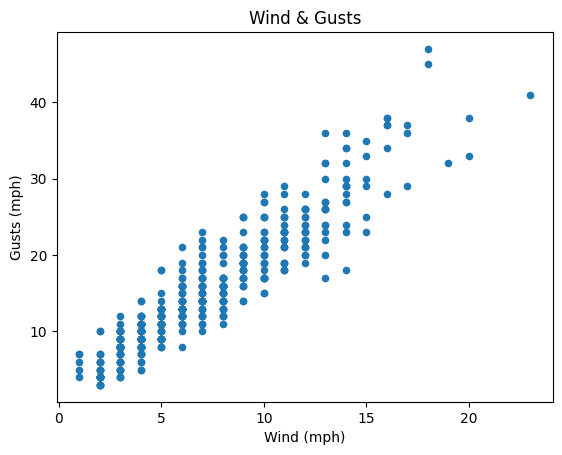

In [10]:
df_gust = df.copy()
df_gust = pd.get_dummies(df_gust, columns=['season'])
df_gust.dropna().plot.scatter('wind', 'gusts')
plt.title('Wind & Gusts')
plt.xlabel('Wind (mph)')
plt.ylabel('Gusts (mph)');

This scatterplot indicates a linear relationship between Wind and Gusts. Therefore, 
I'll first try to use
Linear Regression and predict the *Gusts* value based on *Wind* speed.

MSE: 7.7802280324569315


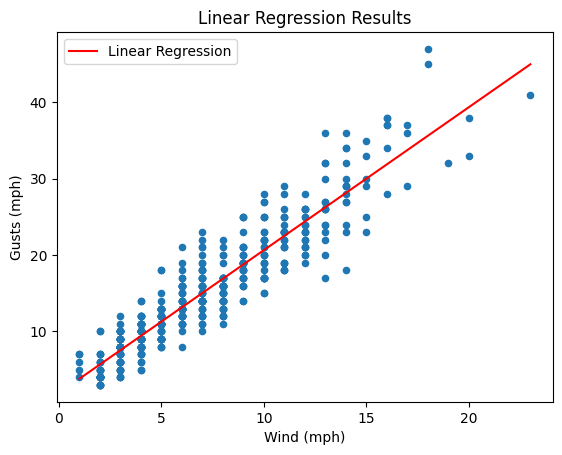

In [11]:
# prep data
non_missing = df_gust.dropna(subset=['gusts'])
missing = df_gust[df_gust['gusts'].isnull()]

X_train = non_missing[['wind']].values
y_train = non_missing['gusts'].values

# train regression model
lr_wind = LinearRegression()
lr_wind.fit(X_train, y_train)
print('MSE:', mean_squared_error(y_train, lr_wind.predict(X_train)))

# plot data points & regression line
m, b = lr_wind.coef_[0], lr_wind.intercept_
x_line = np.linspace(df_gust['wind'].values.min(), df_gust['wind'].values.max())
y_line = m * x_line + b
df_gust.dropna().plot.scatter('wind', 'gusts');
plt.plot(x_line, y_line, color='red', label='Linear Regression')
plt.title('Linear Regression Results')
plt.xlabel('Wind (mph)')
plt.ylabel('Gusts (mph)')
plt.legend();

Linear regression does a pretty good job approximating *Gusts* value from only the
*Wind* feature. However, if it used all the features for predictions rather
than just *Wind*, would accuracy improve?

In [12]:
X_train = non_missing.drop(columns=['date', 'time', 'gusts', 'label']).values
y_train = non_missing['gusts'].values

# train model
lr_all = LinearRegression()
lr_all.fit(X_train, y_train)
print('MSE:', mean_squared_error(y_train, lr_all.predict(X_train)))

MSE: 5.671917788266195


This gives a lower mean squared error (MSE) so I'll be using all features to predict
the missing *Gusts* data.

In [13]:
X_missing = missing.drop(columns=['date', 'time', 'gusts', 'label']).values
df.loc[df['gusts'].isnull(), 'gusts'] = lr_all.predict(X_missing).round()
df.head()

,date,time,temp,feels_like,humidity,uv,wind,gusts,label,season,season_sin,season_cos,time_sin,time_cos
0,2023-07-11,13:55,80,80,0.44,9,4,8.0,none,summer,1.224647e-16,-1.0,-0.4810,-0.8767
1,2023-07-12,12:44,83,83,0.45,9,4,8.0,none,summer,1.224647e-16,-1.0,-0.1908,-0.9816
2,2023-07-13,20:15,75,78,0.79,0,4,7.0,none,summer,1.224647e-16,-1.0,-0.8315,0.5556
3,2023-07-17,17:38,82,83,0.49,3,5,9.0,none,summer,1.224647e-16,-1.0,-0.9954,-0.0958
4,2023-07-22,18:03,75,76,0.58,2,4,7.0,none,summer,1.224647e-16,-1.0,-0.9999,0.0131


### Feature Engineering
For the final preprocessing step, we engineer some useful weather metrics from
our existing feature. This includes:
- Heat Index (https://en.wikipedia.org/wiki/Heat_index)
- Wind chill (https://www.weather.gov/safety/cold-wind-chill-chart)
- Difference between actual temp and feels like temp

In [14]:
def calculate_wind_chill(temp, wind_mph):
    if temp > 50 or wind_mph < 3:
        return temp
    return (
        35.74 + 0.6215 * temp
        - 35.75 * (wind_mph ** 0.16)
        + 0.4275 * temp * (wind_mph ** 0.16)
    )

def calculate_heat_index(temp, humidity):
    if temp < 80 or humidity < 40:
        return temp
    return (
        -42.379 
        + 2.04901523 * temp 
        + 10.14333127 * humidity
        - 0.22475541 * temp * humidity 
        - 0.00683783 * temp ** 2
        - 0.05481717 * humidity ** 2 
        + 0.00122874 * temp ** 2 * humidity
        + 0.00085282 * temp * humidity ** 2 
        - 0.00000199 * temp ** 2 * humidity ** 2
    )

def tempeels_diff(temp, feels_like):
    return feels_like - temp

df['wind_chill'] = df.apply(lambda row: calculate_wind_chill(row['temp'], row['wind']), axis=1)
df['heat_index'] = df.apply(lambda row: calculate_heat_index(row['temp'], row['humidity']), axis=1)
df['feels_diff'] = df.apply(lambda row: tempeels_diff(row['temp'], row['feels_like']), axis=1)

## Data Analysis & Visualizations

### Target Class Distribution
I need to check the distribution for my labels since heavy class imbalances can
skew the results and metrics for my models.

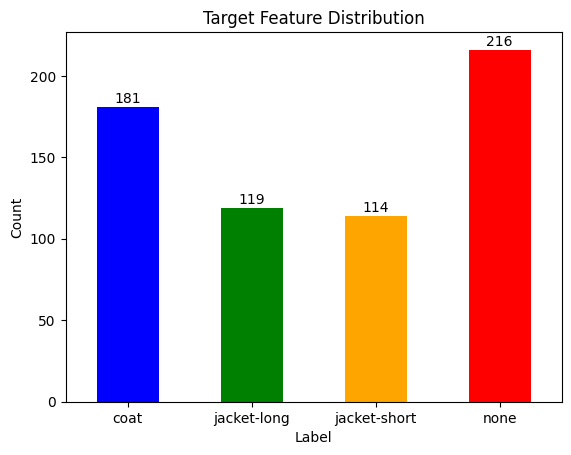

In [15]:
label_distr = df['label'].value_counts().sort_index()
colors = [COLOR_MAPPING[label] for label in label_distr.index]

ax = label_distr.plot(kind='bar', color=colors)
for i, count in enumerate(label_distr):
    ax.text(i, count + 5, f'{label_distr.iloc[i]}', ha='center', va='center')

plt.title('Target Feature Distribution')
plt.xticks(rotation=0)
plt.xlabel('Label')
plt.ylabel('Count');

Although it's not perfectly even, I don't believe these imbalances will significantly
affect my results.

### Date Distribution
Here, I check the distribution of target values across the months.

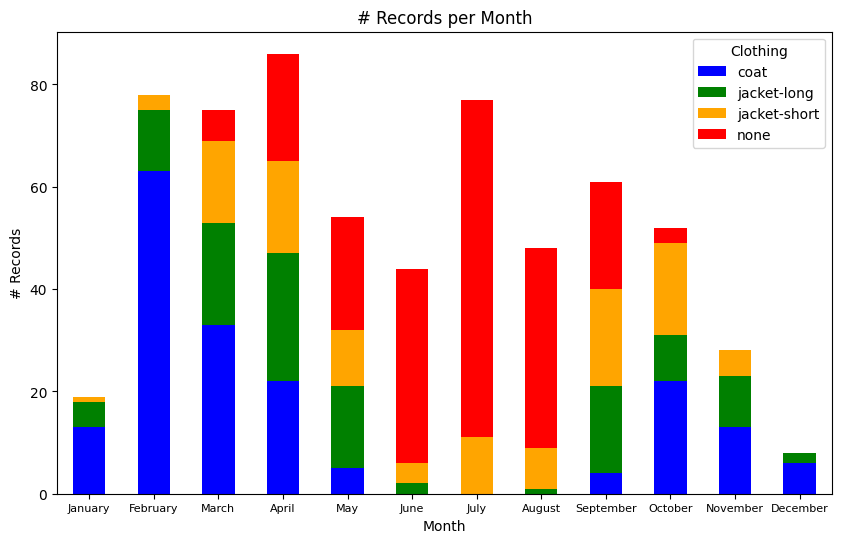

In [16]:
df_date = df[['date', 'label']].copy()
df_date['month'] = df_date['date'].dt.month_name()
month_group = df_date.groupby(['month', 'label']).size().reset_index(name='count')
pivot = month_group.pivot(index='month', columns='label', values='count')
pivot = pivot.reindex(MONTHS)

ax = pivot.plot(kind='bar', stacked=True, figsize=(10, 6), color=['blue', 'green', 'orange', 'red'])
plt.title('# Records per Month')
plt.xlabel('Month')
plt.ylabel('# Records')
plt.xticks(rotation=0, size=8)
plt.legend(title='Clothing');

### Time Distribution

I can also repeat the process for the time of day.

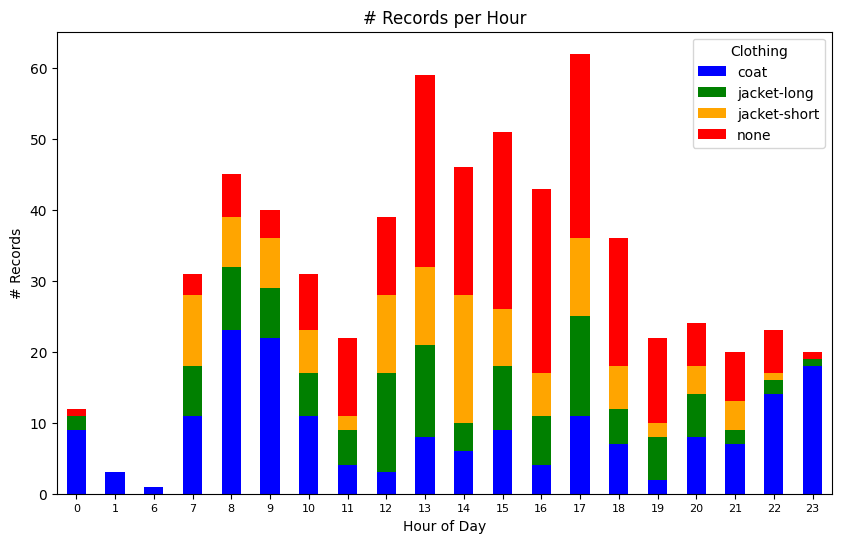

In [17]:
df_time = df[['time', 'label']].copy()
df_time['time'] = [int(time.split(':')[0]) for time in df_time['time'].astype(str)]

time_group = df_time.groupby(['time', 'label']).size().reset_index(name='count')
pivot = time_group.pivot(index='time', columns='label', values='count')

ax = pivot.plot(kind='bar', stacked=True, figsize=(10, 6), color=['blue', 'green', 'orange', 'red'])
plt.title('# Records per Hour')
plt.xlabel('Hour of Day')
plt.ylabel('# Records')
plt.xticks(rotation=0, size=8)
plt.legend(title='Clothing');

### Boxplots

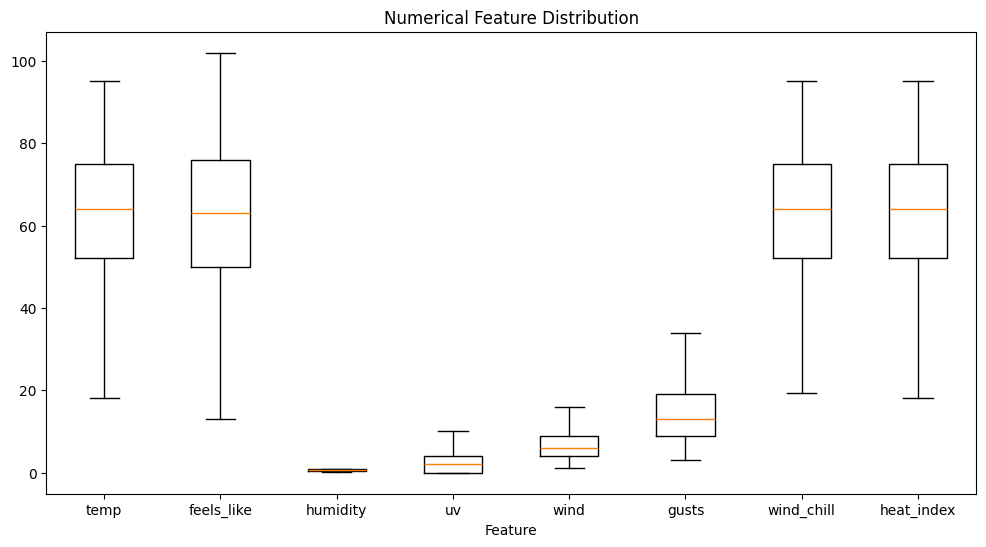

In [18]:
numeric_columns = df[[
    'temp',
    'feels_like',
    'humidity',
    'uv',
    'wind',
    'gusts',
    'wind_chill',
    'heat_index'
]]
plt.figure(figsize=(12, 6))
plt.boxplot(numeric_columns, tick_labels=numeric_columns.columns, showfliers=False)
plt.title('Numerical Feature Distribution')
plt.xlabel('Feature');

### Correlation Matrix

C:\Users\Me\AppData\Local\Temp\ipykernel_452\2985024179.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_corr.replace({'none': 1, 'jacket-short': 2, 'jacket-long': 3, 'coat': 4}, inplace=True)


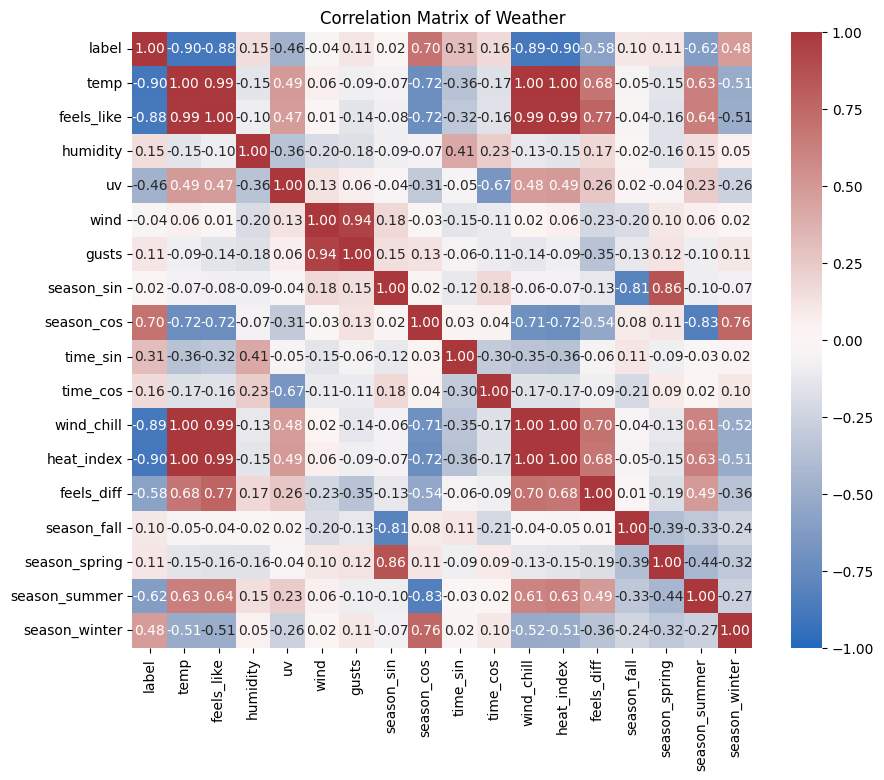

In [19]:
df_corr = df.copy()

# filter features
df_corr.replace({'none': 1, 'jacket-short': 2, 'jacket-long': 3, 'coat': 4}, inplace=True)
df_corr.drop(columns=['date', 'time'], inplace=True)
df_corr = pd.get_dummies(df_corr, columns=['season'])
columns = ['label'] + [col for col in df_corr.columns if col != 'label']
df_corr = df_corr[columns]

# normalize numerical data
scaler = StandardScaler()
numeric_columns = df_corr.select_dtypes(include=['number']).columns
df_corr[numeric_columns] = scaler.fit_transform(df_corr[numeric_columns])

# get correlation matrix
corr_matrix = df_corr.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    vmin=-1,
    vmax=1,
    fmt='.2f',
    annot=True,
    cmap='vlag'
)
plt.title("Correlation Matrix of Weather");

### Principal Component Analysis (PCA)

First we need to preprocess the data. We will be recycling the results from our
correlation matrix since the steps are similar. We just need to re-adjust the
target feature.

In [20]:
df_pca = df_corr.copy()
df_pca['label'] = df['label']
df_pca['label'].replace({'none': '1', 'jacket-short': '2', 'jacket-long': '3', 'coat': '4'}, inplace=True)

C:\Users\Me\AppData\Local\Temp\ipykernel_452\2007477042.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_pca['label'].replace({'none': '1', 'jacket-short': '2', 'jacket-long': '3', 'coat': '4'}, inplace=True)


Next, we will start off with reducing features to just 2, which we can then plot
on a 2D scatter plot.

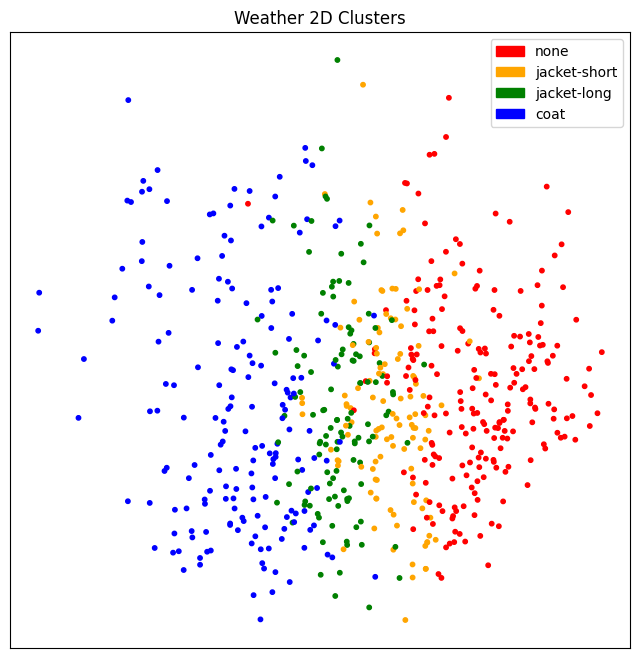

In [21]:
# reduce to 2 components
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(df_pca.drop(columns=['label']))

# custom color map
custom_cmap = mcolors.ListedColormap(COLOR_MAPPING.values())

# 2D scatter plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=df_pca['label'].astype(int),
    s=10,
    cmap=custom_cmap,
)
ax.set_xticks([])
ax.set_yticks([])

# Add legend
handles = [mpatches.Patch(color=color, label=label) for label, color in COLOR_MAPPING.items()]
plt.legend(handles=handles, loc='best')
plt.title('Weather 2D Clusters');

Finally, we can expand on our code to plot on a 3D scatter plot instead.

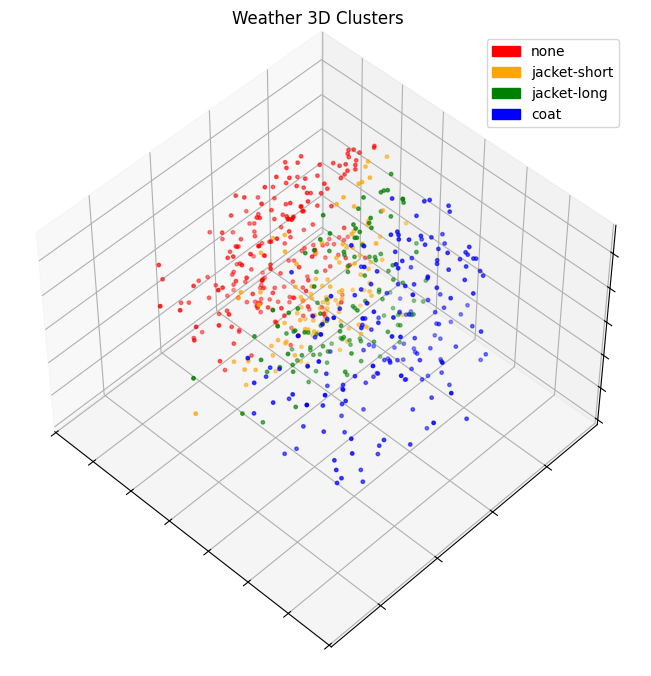

In [22]:
# reduce to 3 components
pca_3d = PCA(n_components=3)
X_3d = pca_3d.fit_transform(df_pca.drop(columns=['label']))

# custom color map
custom_cmap = mcolors.ListedColormap(COLOR_MAPPING.values())

# 3D scatter plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d', elev=48, azim=134)
ax.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=df_pca['label'].astype(int),
    s=6,
    cmap=custom_cmap
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# legend & title
handles = [mpatches.Patch(color=color, label=label) for label,color in COLOR_MAPPING.items()]
plt.legend(handles=handles, loc='best')
plt.title('Weather 3D Clusters');

## Machine Learning Model Experiments

### ML Libraries

In [23]:
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

### Preprocess

In [24]:
df_ml = df.copy()
df_ml.head()

,date,time,temp,feels_like,humidity,uv,wind,gusts,label,season,season_sin,season_cos,time_sin,time_cos,wind_chill,heat_index,feels_diff
0,2023-07-11,13:55,80,80,0.44,9,4,8.0,none,summer,1.224647e-16,-1.0,-0.4810,-0.8767,80.0,80,0
1,2023-07-12,12:44,83,83,0.45,9,4,8.0,none,summer,1.224647e-16,-1.0,-0.1908,-0.9816,83.0,83,0
2,2023-07-13,20:15,75,78,0.79,0,4,7.0,none,summer,1.224647e-16,-1.0,-0.8315,0.5556,75.0,75,3
3,2023-07-17,17:38,82,83,0.49,3,5,9.0,none,summer,1.224647e-16,-1.0,-0.9954,-0.0958,82.0,82,1
4,2023-07-22,18:03,75,76,0.58,2,4,7.0,none,summer,1.224647e-16,-1.0,-0.9999,0.0131,75.0,75,1


In [25]:
# drop Date and Time
df_ml.drop(columns=['date', 'time'], inplace=True)

# one-hot encode season
df_ml = pd.get_dummies(df_ml, columns=['season'])

# split into X/y
X = df_ml.drop(columns=['label'])
y = df_ml['label']

# split off testing data
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=RANDOM_STATE,
    stratify=y
)

# split rest into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=2/9,
    random_state=RANDOM_STATE,
    stratify=y_temp)

# normalize
numeric_columns = X_train.select_dtypes(include=['number']).columns
scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_val[numeric_columns] = scaler.transform(X_val[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

In [26]:
print('Train distribution:', y_train.value_counts().to_string())
print('train size:', X_train.shape[0])

print('\nVal distribution:', y_val.value_counts().to_string())
print('Val size:', X_val.shape[0])

print('\nTest distribution:', y_test.value_counts().to_string())
print('Test size:', X_test.shape[0])

Train distribution: label
none            151
coat            127
jacket-long      83
jacket-short     80
train size: 441

Val distribution: label
none            43
coat            36
jacket-long     24
jacket-short    23
Val size: 126

Test distribution: label
none            22
coat            18
jacket-long     12
jacket-short    11
Test size: 63


### Logistic Regression

In [27]:
lr_params = {
    'solver': ['saga', 'sag', 'newton-cg'],
    'penalty': [None, 'l2']
}

lr_model = LogisticRegression(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    max_iter=5000
)

lr_grid = GridSearchCV(lr_model, lr_params, cv=5, scoring=['accuracy', 'f1_macro'], refit='f1_macro')
lr_grid.fit(X_train, y_train)

print('Logistic Regression Best Params:', lr_grid.best_params_)
print('Logistic Regression Best Score:', lr_grid.best_score_)


Logistic Regression Best Params: {'penalty': 'l2', 'solver': 'saga'}
Logistic Regression Best Score: 0.7771408066852897


### Decision Tree

In [28]:
dt_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 5, 10],
    'max_features': [None, 'sqrt', 'log2']
}

dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced'
)

dt_grid = GridSearchCV(dt_model, dt_params, cv=5, scoring=['accuracy', 'f1_macro'], refit='f1_macro')
dt_grid.fit(X_train, y_train)

print('DecisionTree Best Params:', dt_grid.best_params_)
print('DecisionTree Best Score:', dt_grid.best_score_)

DecisionTree Best Params: {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5}
DecisionTree Best Score: 0.7633844129292997


### KNN

In [29]:
knn_params = {
    'n_neighbors': np.arange(1, 16, 2),
    'weights': ['uniform', 'distance'],
    'p': [1, 2, 3, 4, 5],
    'algorithm': ['ball_tree', 'kd_tree', 'brute']
}

knn_model = KNeighborsClassifier(
    n_jobs=-2
)

knn_grid = GridSearchCV(knn_model, knn_params, cv=5, scoring=['accuracy', 'f1_macro'], refit='f1_macro')
knn_grid.fit(X_train, y_train)

print('KNN Best Params:', knn_grid.best_params_)
print('KNN Best Score:', knn_grid.best_score_)

KNN Best Params: {'algorithm': 'ball_tree', 'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
KNN Best Score: 0.7831794651652372


### Neural Network

c:\Users\Me\Documents\Projects\WeatherML\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


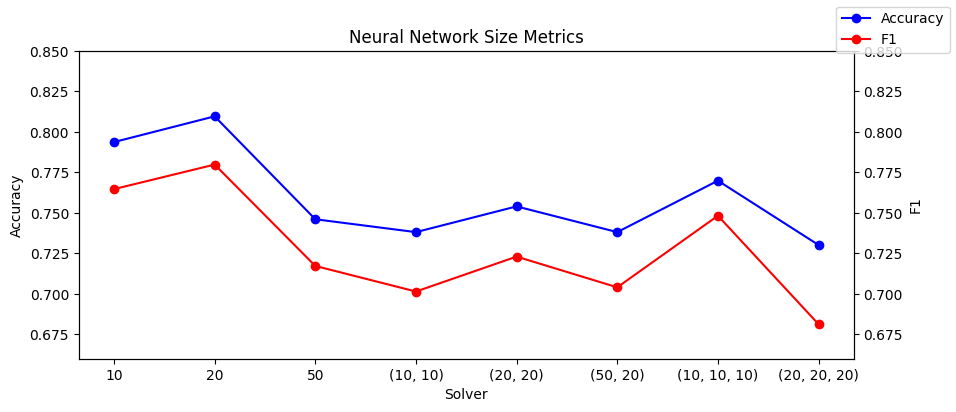

In [30]:
nn_sizes = [
    (10), 
    (20), 
    (50), 
    (10, 10), 
    (20, 20), 
    (50, 20), 
    (10, 10, 10), 
    (20, 20, 20)
]

nn_size_acc = []
nn_size1 = []

for size in nn_sizes:
    mlp = MLPClassifier(
        random_state=RANDOM_STATE,
        max_iter=2000,
        hidden_layer_sizes=size
    )
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_val)
    nn_size_acc.append(accuracy_score(y_val, y_pred))
    nn_size1.append(f1_score(y_val, y_pred, average='macro'))

nn_sizes = [str(size) for size in nn_sizes]

fig, ax1 = plt.subplots(figsize=(10,4))

ax1.plot(nn_sizes, nn_size_acc, 'b-', label='Accuracy', marker='o')
ax1.set_xlabel('Solver')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0.66, 0.85)

ax2 = ax1.twinx()
ax2.plot(nn_sizes, nn_size1, 'r-', label='F1', marker='o')
ax2.set_ylabel('F1')
ax2.set_ylim(0.66, 0.85)

plt.title('Neural Network Size Metrics')
fig.legend(loc='upper right');

In [31]:
nn_params = {
    'hidden_layer_sizes' : [
        (10, 10, 10),
        (20)
    ],
    'activation': ['logistic', 'tanh', 'relu'],
    'solver': ['lbfgs', 'adam'],
    'alpha': [0.0001, 0.001, 0.01]
}

nn_model = MLPClassifier(
    random_state=RANDOM_STATE,
    max_iter=5000
)

nn_grid = GridSearchCV(nn_model, nn_params, cv=5, scoring=['accuracy', 'f1_macro'], refit='f1_macro')
nn_grid.fit(X_train, y_train)

print('Neural Network Best Params:', nn_grid.best_params_)
print('Neural Network Best Score:', nn_grid.best_score_)

c:\Users\Me\Documents\Projects\WeatherML\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Me\Documents\Projects\WeatherML\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


Neural Network Best Params: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': 20, 'solver': 'adam'}
Neural Network Best Score: 0.7728825456827384


## Compare Performance

### Scoring Function
To compare the performance across the different model types, I'll first define a
helper method to score a model. It reports several metrics for the model as well
as creating a confusion matrix.

In [47]:
def score_model(y_true, y_pred, label):
    # calc matrics
    acc = accuracy_score(y_true, y_pred)
    p = precision_score(y_true, y_pred, average="macro")
    r = recall_score(y_true, y_pred, average="macro")
    f1 = f1_score(y_true, y_pred, average="macro")

    # print metrics
    print(f'Params: {label}')
    print(' - Accuracy: ', acc)
    print(' - Precision:', p)
    print(' - Recall:   ', r)
    print(' - F1:       ', f1)

    # display confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['coat', 'jacket-long', 'jacket-short', 'none'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'{label}')
    plt.show()

    # return metrics
    return acc, p, r, f1

### Logistic Regression

Params: Logistic Regression
 - Accuracy:  0.8174603174603174
 - Precision: 0.8026766655431974
 - Recall:    0.796102046102046
 - F1:        0.7967180254922754


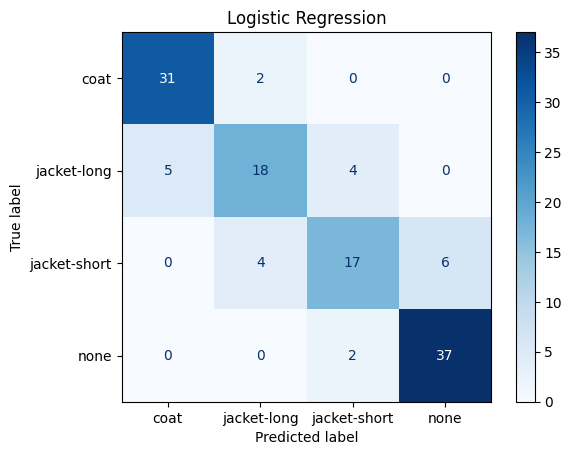

In [48]:
best_lr = lr_grid.best_estimator_
lr_ypred = best_lr.predict(X_val)
lr_results = score_model(lr_ypred, y_val, label='Logistic Regression')

### Bagged Logistic Regression

Params: Bagged Logistic Regression
 - Accuracy:  0.8015873015873016
 - Precision: 0.7818433322098639
 - Recall:    0.7760154660154661
 - F1:        0.7771849213749396


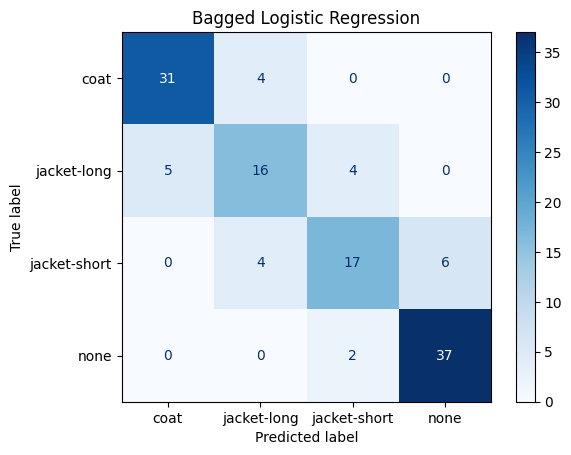

In [49]:
bagged_lr = BaggingClassifier(
    random_state=RANDOM_STATE,
    estimator=best_lr,
    n_estimators=10,
    n_jobs=-2
)

bagged_lr.fit(X_train, y_train)
bagged_lr_ypred = bagged_lr.predict(X_val)
bagged_results = score_model(bagged_lr_ypred, y_val, label='Bagged Logistic Regression')

### Decision Tree

Params: Decision Tree
 - Accuracy:  0.7619047619047619
 - Precision: 0.7284013032243568
 - Recall:    0.732621473354232
 - F1:        0.7279779653731985


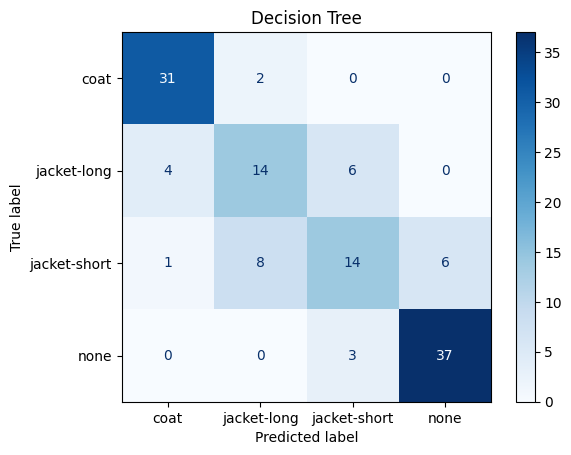

In [50]:
best_dt = dt_grid.best_estimator_
lr_ypred = best_dt.predict(X_val)
dt_results = score_model(lr_ypred, y_val, label='Decision Tree')

### Random Forest

Params: Random Forest
 - Accuracy:  0.8174603174603174
 - Precision: 0.8022237669924728
 - Recall:    0.795500700280112
 - F1:        0.7972252113433862


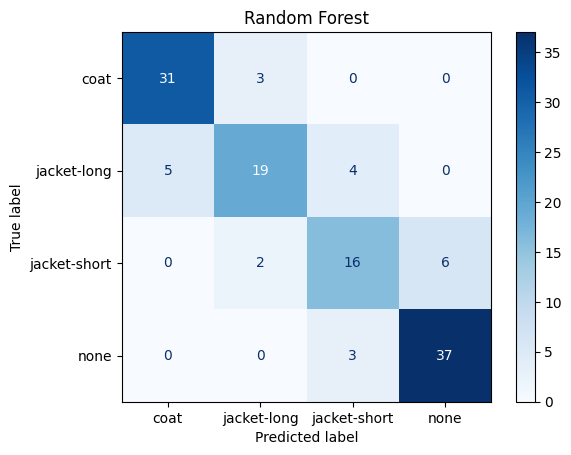

In [51]:
forest = BaggingClassifier(
    random_state=RANDOM_STATE,
    estimator=best_dt,
    n_estimators=10,
    n_jobs=-2
)

forest.fit(X_train, y_train)
forest_ypred = forest.predict(X_val)
forest_results = score_model(forest_ypred, y_val, label='Random Forest')

### KNN

Params: KNN
 - Accuracy:  0.7142857142857143
 - Precision: 0.6695982193012021
 - Recall:    0.6705705705705706
 - F1:        0.66876145439411


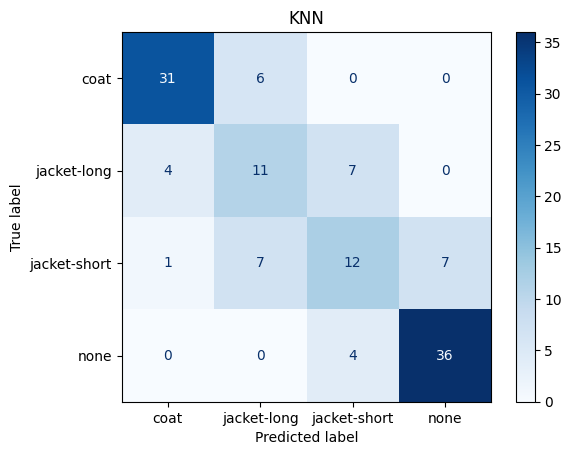

In [52]:
best_knn = knn_grid.best_estimator_
lr_ypred = best_knn.predict(X_val)
knn_results = score_model(lr_ypred, y_val, label='KNN')

### Neural Network

Params: Neural Network
 - Accuracy:  0.7698412698412699
 - Precision: 0.740629564093922
 - Recall:    0.7386485275598178
 - F1:        0.7328393810073955


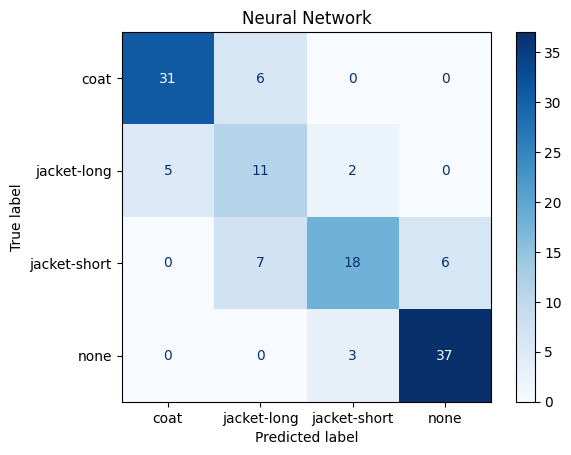

In [53]:
best_nn = nn_grid.best_estimator_
lr_ypred = best_nn.predict(X_val)
nn_results = score_model(lr_ypred, y_val, label='Neural Network')

### Naive Bayes Classifier

Params: Naive Bayes
 - Accuracy:  0.753968253968254
 - Precision: 0.6919482361532412
 - Recall:    0.7105429292929294
 - F1:        0.6914377289377289


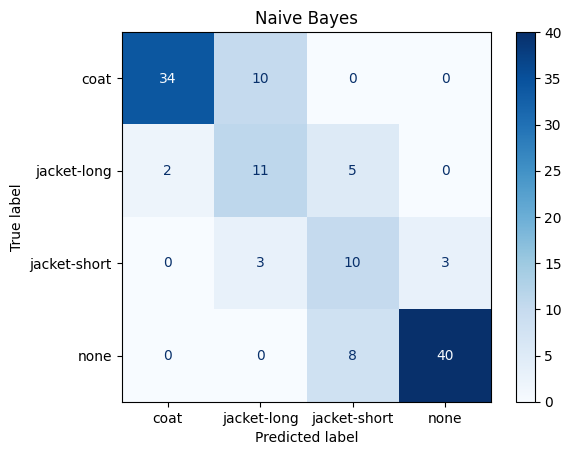

In [54]:
best_nb = GaussianNB()
best_nb.fit(X_train, y_train)
nb_ypred = best_nb.predict(X_val)
nb_results = score_model(nb_ypred, y_val, label='Naive Bayes')

### Results


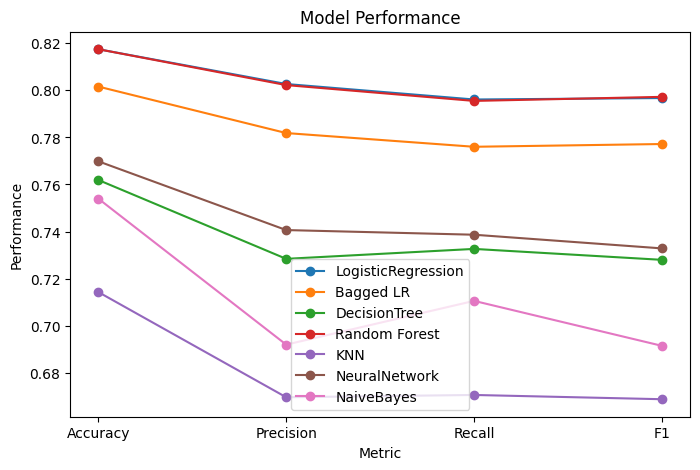

In [55]:
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1']
models = ['LogisticRegression', 'Bagged LR', 'DecisionTree', 'Random Forest', 'KNN', 'NeuralNetwork', 'NaiveBayes']
metrics = np.array([lr_results, bagged_results, dt_results, forest_results, knn_results, nn_results, nb_results]).T

fig, ax = plt.subplots(figsize=(8,5))
for i, label in enumerate(models):
    ax.plot(
        metric_labels,
        metrics[:, i],
        marker='o',
        label=label
    )

ax.set_xlabel('Metric')
ax.set_ylabel('Performance')
ax.set_title('Model Performance')
ax.legend()
plt.show()

We have a tie in accuracy between the random forest and logistic regression.
However, the forest has slightly better metrics for precision, recall, and F1.

Params: Final Best Model
 - Accuracy:  0.8888888888888888
 - Precision: 0.8724747474747475
 - Recall:    0.8717171717171718
 - F1:        0.8673520923520923


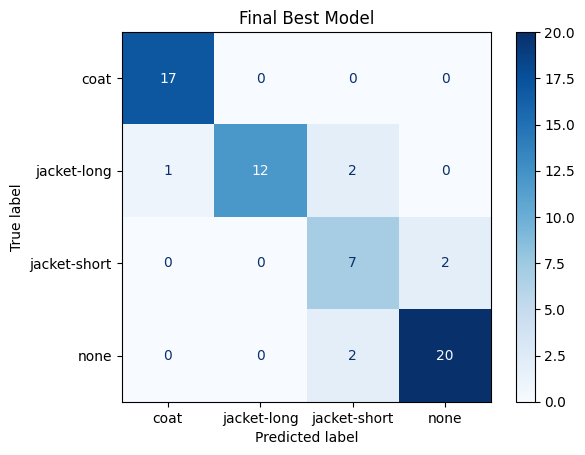

In [56]:
best_model = forest
y_pred = best_model.predict(X_test)
score_model(y_pred, y_test, label='Final Best Model');

## Export Model
I can now export the best model to be used in a runner program.

In [57]:
import joblib

joblib.dump(scaler, '../models/best.scaler')
joblib.dump(best_model, '../models/best.model');